# COMP1117 Tutorial 7 — Coding Practice (Strings)

November 2026

Use Python 3; no extra packages are needed.

We will recall string operations, run short demonstrations, and then write functions. Predict each demonstration before running it. The classroom PDF includes worked answers for discussion after each attempt.

The exercise functions return values; use `print()` only when trying a call. Each task is followed by one possible answer from the slides: attempt the task first, then compare. Add a test of your own.

## From concepts to code

You have used string methods, indexing, slicing and loops. Today we will choose and combine those operations, reuse functions and test the result.

Before coding, identify the input, the value to return and one result you can check by hand.

## String methods return new values

A string cannot be changed in place. Save or use the value returned by a method.

Predict the output, then run the example.

In [ ]:
message = 'Hello!'
message.lower()
print(message)

quiet = message.lower()
print(quiet)

Calling lower() does not change message. The second call assigns its result to quiet. Inside a function, return the new value so that the caller can use it.

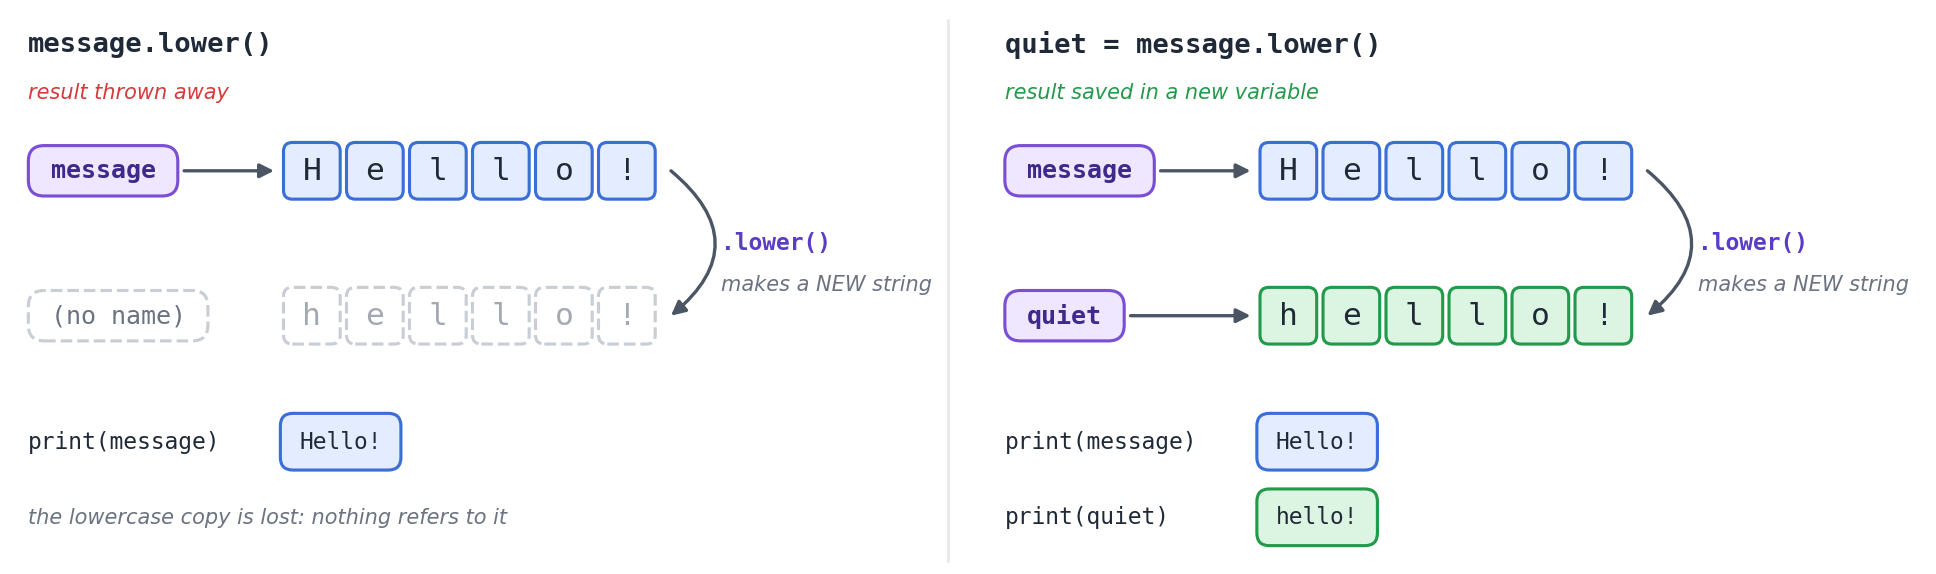

**Discuss:** What would happen if the function printed the result but did not return it?

## From text to words, and back

split() produces a list of words. A separator's join() method combines them into a string.

Predict the output, then run the example.

In [ ]:
text = '  red\tblue  '
words = text.split()
print(words)
print(' '.join(words))
print(text.split(' '))

With no argument, split() groups whitespace and drops empty pieces. split(' ') splits only at ordinary spaces. The separator in ' '.join(words) is one ordinary space.

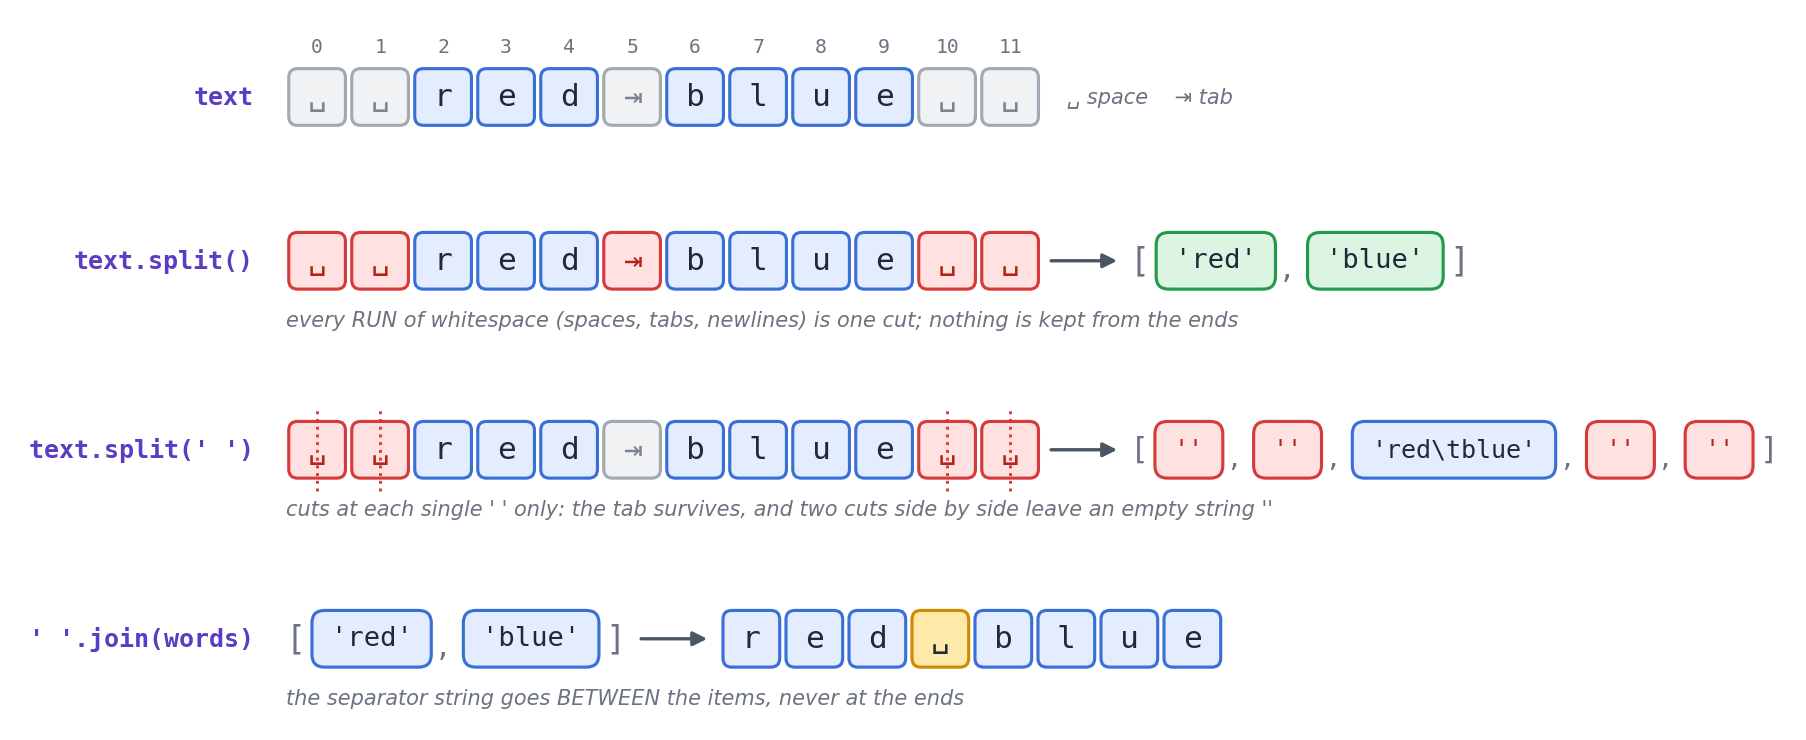

**Discuss:** What changes if the separator in join() is an empty string?

## Indexing, slicing and repetition

Indexing selects one character. Slicing selects a sequence of characters.

Predict the output, then run the example.

In [ ]:
word = 'Python'
print(word[0], word[-1])
print(word[1:4])
print(word[::-1])
print('*' * 3)

The stop index in [1:4] is excluded. A step of -1 reverses the string. Repetition with * builds a new string. Check for an empty string before taking its first character.

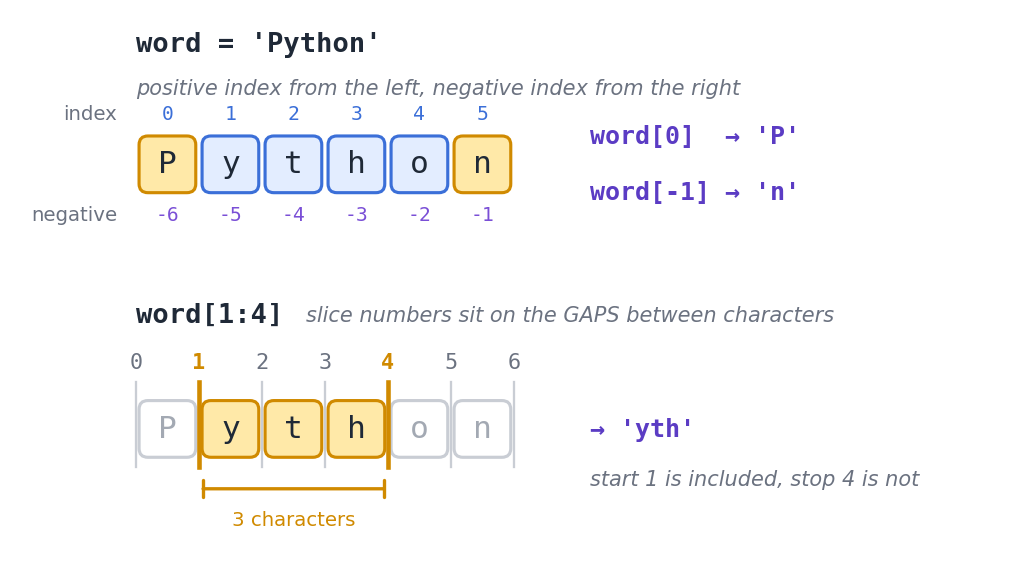

![Reversing with [::-1] and repeating with *](attachment:04_reverse_and_repeat.png)

**Discuss:** Which of these operations would fail on an empty string: [0], [1:4], or [::-1]?
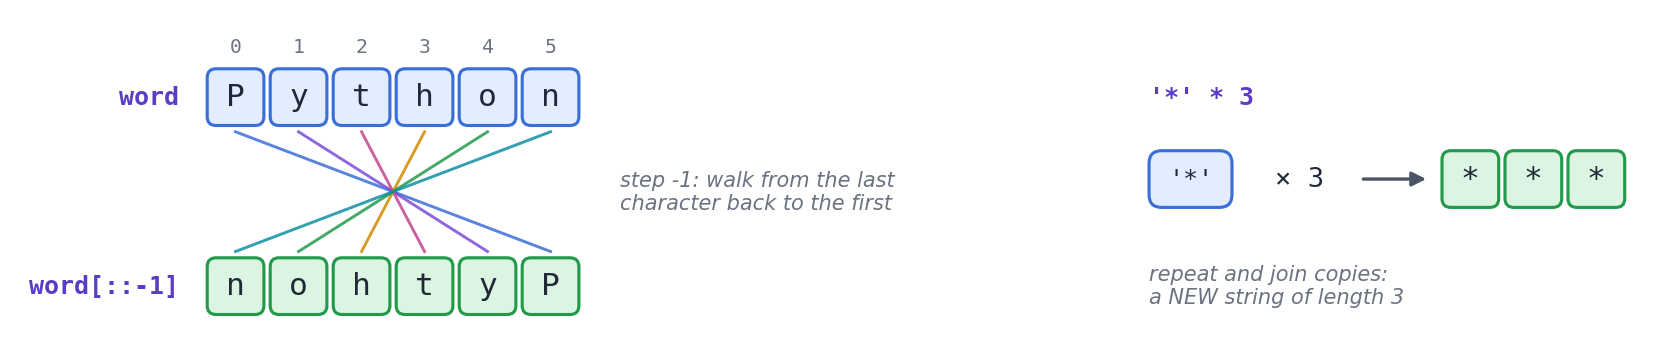

## Build a result with an f-string

Calculate a value first, then choose how to display it.

Predict the output, then run the example.

In [ ]:
total = 10
count = 3
average = total / count
print(f'Average: {average:.1f}')
print(f'Words: {count}\nTotal: {total}')

Use .1f for one decimal place; it does not change average. A newline escape starts a new line. Check for zero words before dividing.

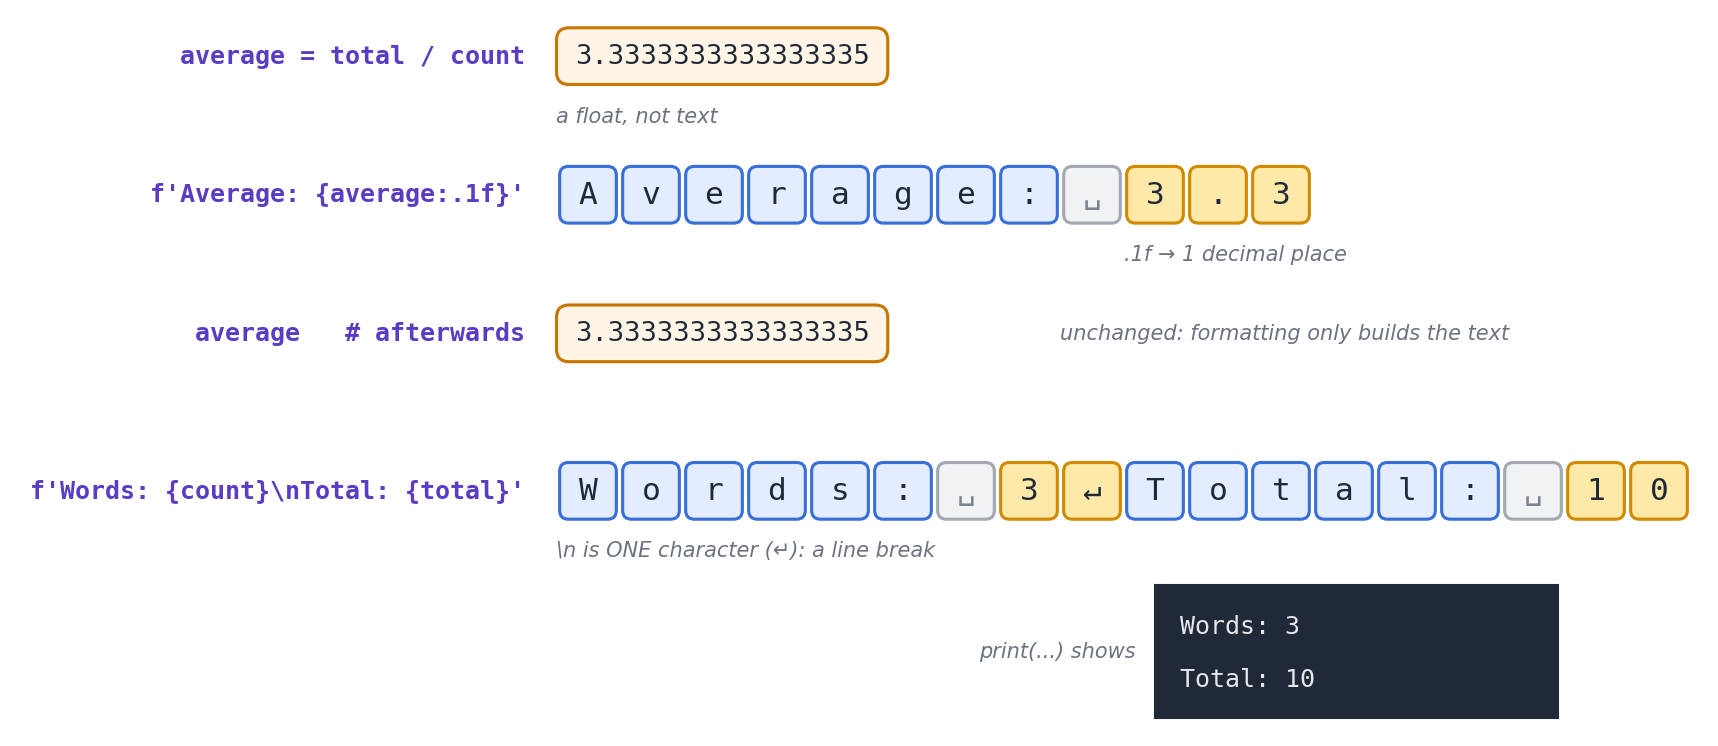

**Discuss:** Does formatting average change the value stored in average?

## Quick check: trace the methods

Predict pieces and joined before running the code. Has original changed?

In [ ]:
original = '  Hi\tTHERE  ! '
pieces = original.lower().replace('!', '').split()
joined = ' '.join(pieces)

### Check your prediction

Run the next cell after discussing your prediction.

In [ ]:
print(pieces)
print(repr(joined))
print(repr(original))

lower() returns lowercase text; replace() removes !; split() makes words; join() puts one space between them. Each step uses the previous result. original is unchanged.

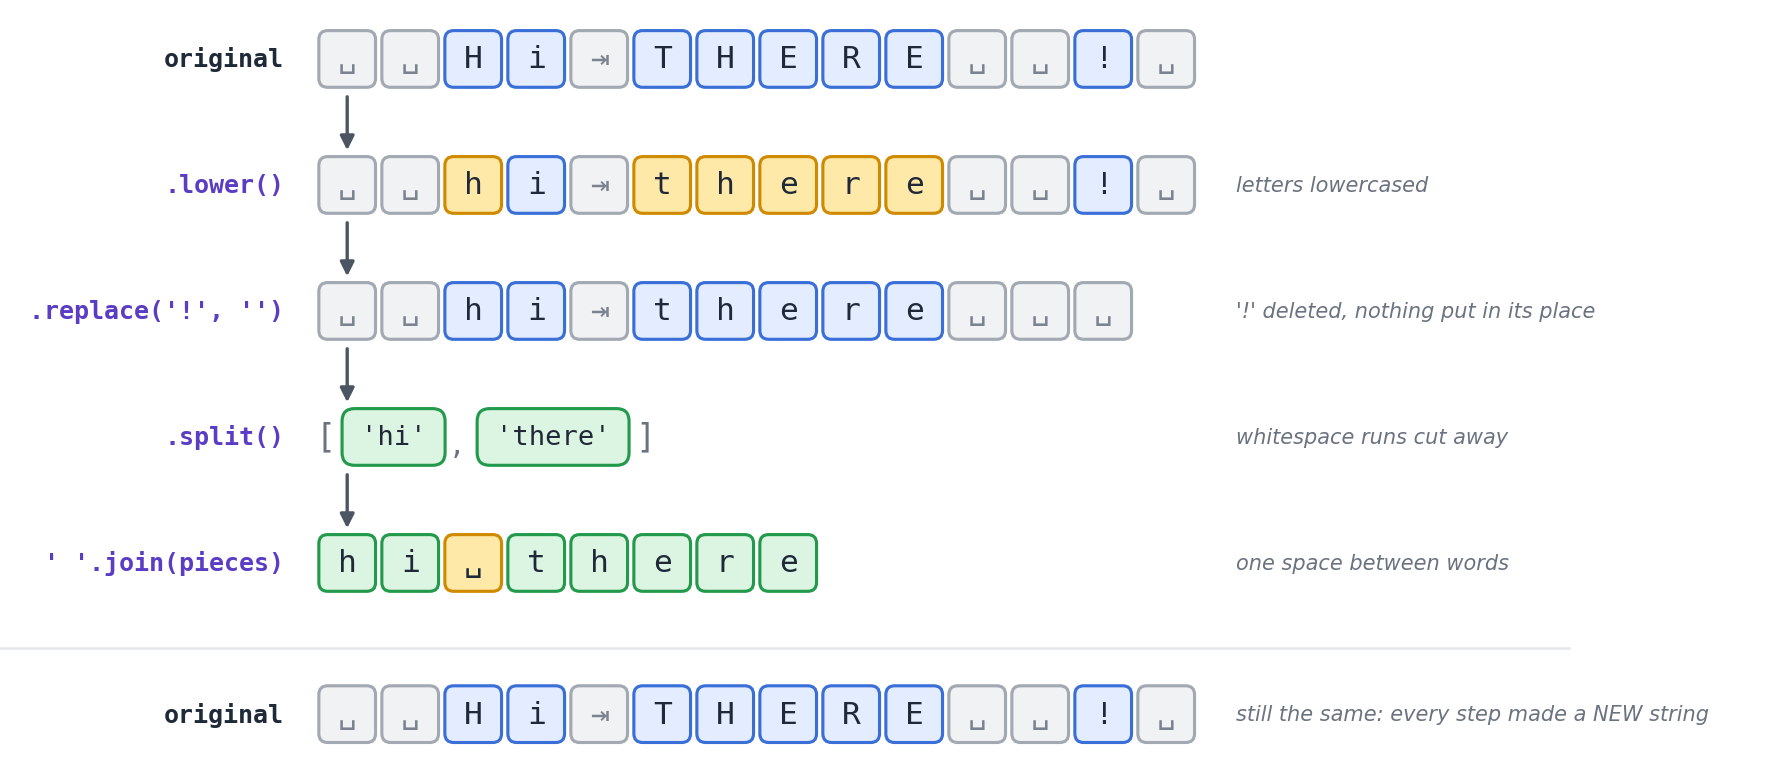

## Task 1: Clean up a message

`normalise_text(text)`

Return a cleaned version of a message.

1. Convert letters to lowercase and remove every exclamation mark (!). Keep all other punctuation and digits.
2. After removing !, replace each run of whitespace with one ordinary space. Remove leading and trailing whitespace.
3. Whitespace follows split() with no argument; it includes spaces, tabs and line breaks (also carriage return, vertical tab and form feed).
4. Return an empty string when nothing remains. Removing ! does not insert a space: 'one!two' becomes 'onetwo'.

Input: text is an ASCII string, possibly empty. It may contain whitespace, digits and punctuation. No input validation is needed.

Return the result; do not print inside the function.

### Examples

```python
normalise_text('  PYTHON\tis Fun!!!  ')
```

Returns `'python is fun'`.

```python
normalise_text('  Keep, THIS? 42! ')
```

Returns `'keep, this? 42'`.

```python
normalise_text('')
```

Returns `''`.


### Follow the text through the steps

Remove ! before making the word list. Otherwise an isolated ! would count as a word. Keep the returned values at each step.

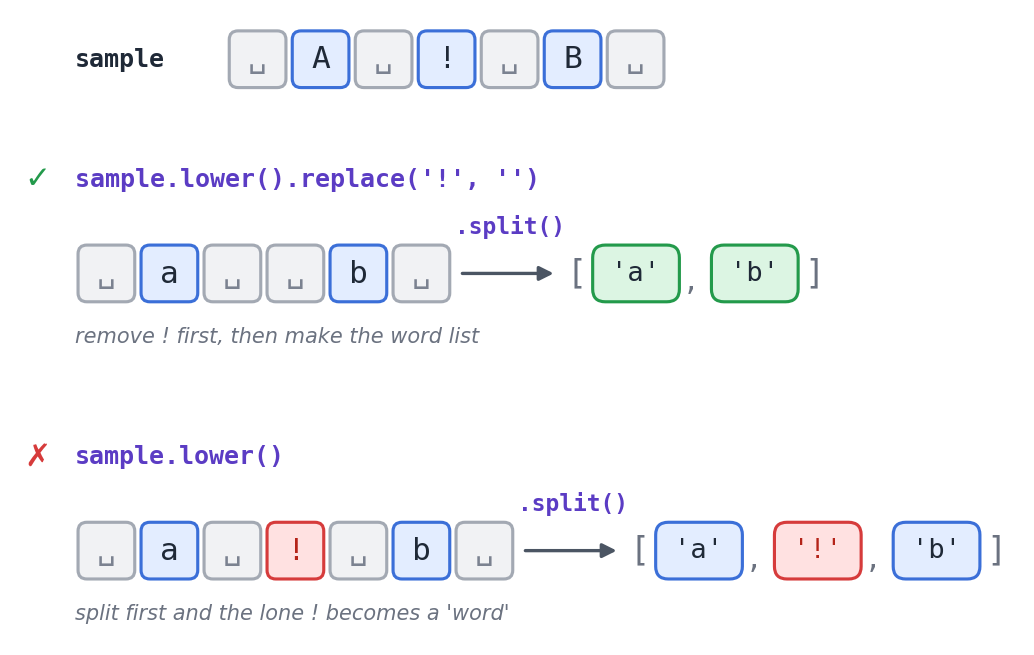

In [ ]:
sample = ' A ! B '
without_bang = sample.lower().replace('!', '')
print(repr(without_bang))
print(without_bang.split())

**Discuss:** Compare deleting ! with replacing it by a space in 'one!two'.

In [ ]:
def normalise_text(text):
    pass


In [ ]:
# Task 1: answer (T7.pdf, slide 11)
def normalise_text(text):
    cleaned = text.lower().replace('!', '')
    return ' '.join(cleaned.split())

Add a different input below and write down its expected result first.

## Task 2: Find the longest word

`word_summary(text)`

Return the word count and the first longest word as a tuple.

1. A word is a non-empty part returned by text.split(). Whitespace separates words; punctuation stays attached and counts towards length.
2. Return (number_of_words, longest_word), preserving the spelling and case of the chosen word.
3. If several words have the same maximum length, return the first one in the input.
4. For empty or whitespace-only input, return (0, ''). Use a loop to find the longest word, not max() or sorting.

Input: text is an ASCII string, possibly empty. Words are defined by whitespace, not by a dictionary. No input validation is needed.

Return the result; do not print inside the function.

### Examples

```python
word_summary('Python is fun')
```

Returns `(3, 'Python')`.

```python
word_summary('red blue gold')
```

Returns `(3, 'blue')`.

```python
word_summary('')
```

Returns `(0, '')`.


### Keep the best word seen so far

Start with longest = ''. Visit each word and update only when the new word is longer. A tie keeps the earlier word.

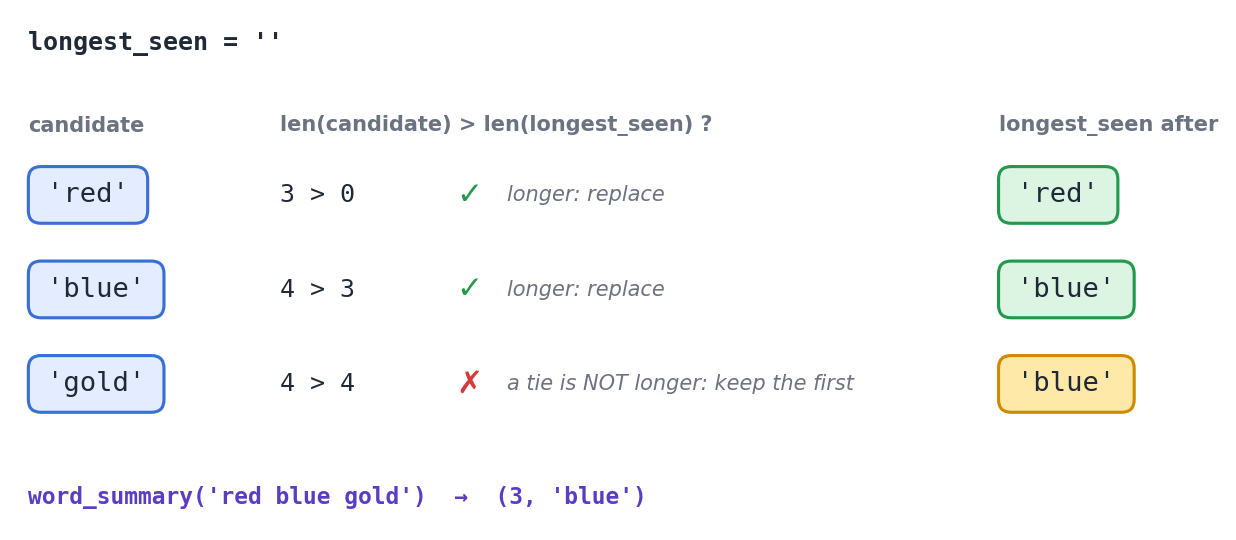

In [ ]:
longest_seen = ''
for candidate in 'red blue gold'.split():
    if len(candidate) > len(longest_seen):
        longest_seen = candidate
    print(candidate, '->', longest_seen)

**Discuss:** Replace > with >= in this demonstration. Which answer changes, and why?

In [ ]:
def word_summary(text):
    pass


In [ ]:
# Task 2: answer (T7.pdf, slide 14)
def word_summary(text):
    words = text.split()
    longest = ''
    for word in words:
        if len(word) > len(longest):
            longest = word
    return len(words), longest

Add a different input below and write down its expected result first.

## Task 3: Build a text report

`text_report(text)`

Combine the first two functions and return a four-line report.

1. Call normalise_text(text), then call word_summary() on the cleaned string. The Ed version supplies both helpers so this task can be attempted independently.
2. The average word length is the sum of the lengths of the cleaned words divided by the word count. Punctuation other than ! counts; separating spaces do not.
3. Return four lines with exactly these labels: Text:, Words:, Longest:, Average length:. Use one space after each colon and one newline between lines.
4. Show the average to one decimal place using an f-string. For no words, use 0.0 and '(none)' as the longest-word display.
5. The Text: line still has one space after its colon for empty text. Do not add a trailing newline.

Input: text is an ASCII string, possibly empty. Use the word and cleaning rules from Tasks 1 and 2. No input validation is needed.

Return the result; do not print inside the function.

### Examples

```python
text_report('  Python\tis FUN!!! ')
```

Returns `'Text: python is fun\nWords: 3\nLongest: python\nAverage length: 3.7'`.

```python
text_report('')
```

Returns `'Text: \nWords: 0\nLongest: (none)\nAverage length: 0.0'`.


### Separate calculation from formatting

First call the two helpers. Then add the word lengths and find the average. Finally return the four lines. len(cleaned) would include the spaces between words.

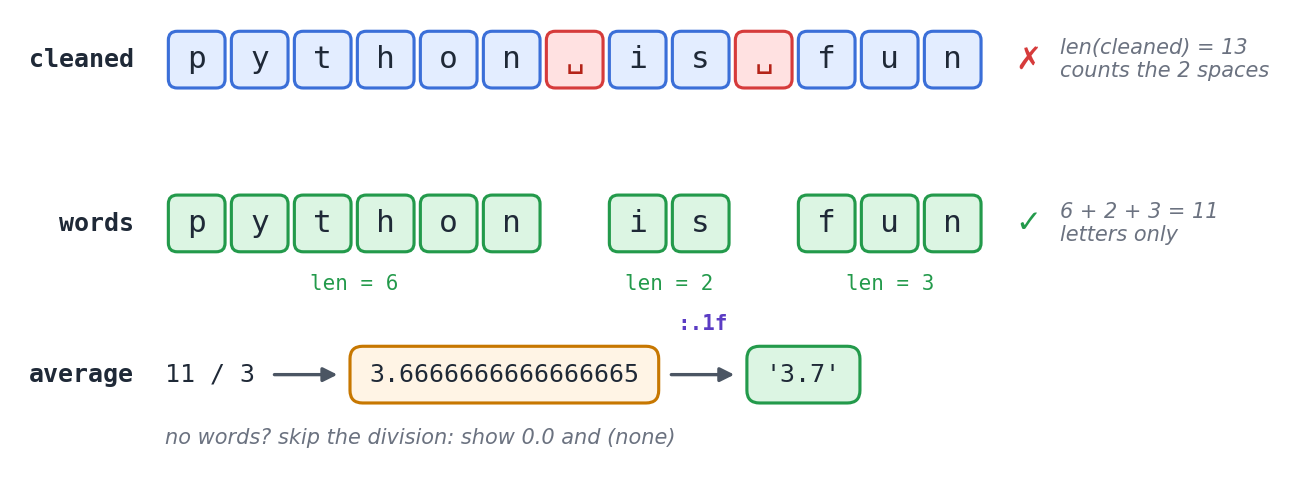

In [ ]:
sample_words = ['python', 'is', 'fun']
letter_total = 0
for item in sample_words:
    letter_total = letter_total + len(item)
print(letter_total)
print(f'{letter_total / len(sample_words):.1f}')

**Discuss:** If sample_words were empty, which line would fail? What result should this task use instead?

Use `normalise_text()` and `word_summary()` from Tasks 1 and 2. To attempt this task independently, use its Ed challenge or the supplied `ed/03_text_report/scaffold/` files, which provide both helpers. The supplied runner is not part of your implementation.

In [ ]:
def text_report(text):
    pass


In [ ]:
# Task 3: answer (T7.pdf, slides 16-18)
def text_report(text):
    cleaned = normalise_text(text)
    word_count, longest = word_summary(cleaned)
    total_length = 0
    for word in cleaned.split():
        total_length = total_length + len(word)
    average = 0.0
    if word_count > 0:
        average = total_length / word_count
    if longest == '':
        longest = '(none)'
    return (f'Text: {cleaned}\n'
            f'Words: {word_count}\n'
            f'Longest: {longest}\n'
            f'Average length: {average:.1f}')

Add a different input below and write down its expected result first.

## Task 4: Name initials

`initials(name)`

Return uppercase initials with a full stop after each initial.

1. Split the name on whitespace. Use the first character of each part, converted to uppercase.
2. Put a full stop after every initial, including the last. Do not insert spaces.
3. The input contains ASCII letters and whitespace only. Empty or whitespace-only input returns ''. A one-letter part is allowed.

Input: name contains only ASCII letters and whitespace, and may be empty. Hyphenated names and punctuation are outside this task's input domain.

Return the result; do not print inside the function.

### Examples

```python
initials('Ada Lovelace')
```

Returns `'A.L.'`.

```python
initials('  alan\tturing ')
```

Returns `'A.T.'`.

```python
initials('')
```

Returns `''`.


### Build the initials one part at a time

split() gives non-empty name parts, so part[0] is safe inside the loop. Add each uppercase initial and its full stop to the result.

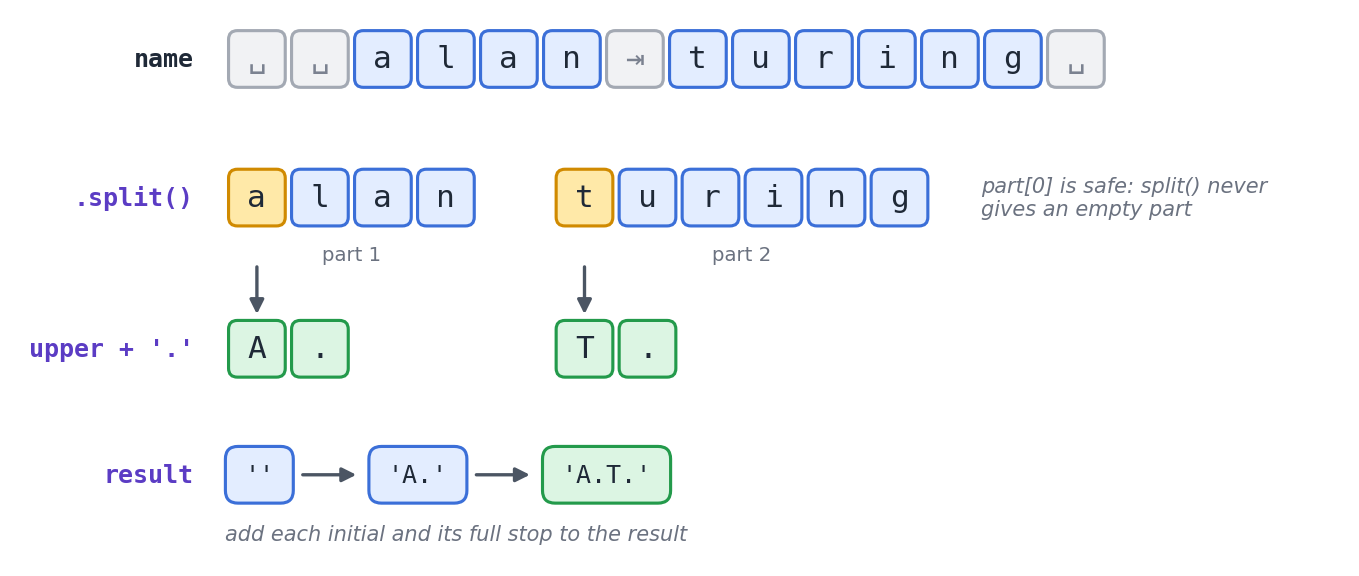

**Discuss:** Trace result for 'alan turing'. What happens when the name contains only whitespace?

In [ ]:
def initials(name):
    pass


In [ ]:
# Task 4: answer (T7.pdf, slide 20)
def initials(name):
    result = ''
    for part in name.split():
        result = result + part[0].upper() + '.'
    return result

Add a different input below and write down its expected result first.

## Task 5: Count one character

`count_character(text, target)`

Count occurrences of a single character, ignoring letter case.

1. target is guaranteed to be exactly one ASCII character. text may be any ASCII string, including empty.
2. Count matches after lowercasing text and target. Spaces and punctuation are valid targets and count literally.
3. Return an integer. Both a loop and str.count() are accepted. Do not count substrings of more than one character.

Input: text is an ASCII string and target is exactly one ASCII character. No validation is required.

Return the result; do not print inside the function.

### Examples

```python
count_character('Banana', 'A')
```

Returns `3`.

```python
count_character('a a', ' ')
```

Returns `1`.

```python
count_character('', 'x')
```

Returns `0`.


### Use the same case for both arguments

To ignore case, lowercase both the text and the target before comparing or counting. Spaces and punctuation are still characters.

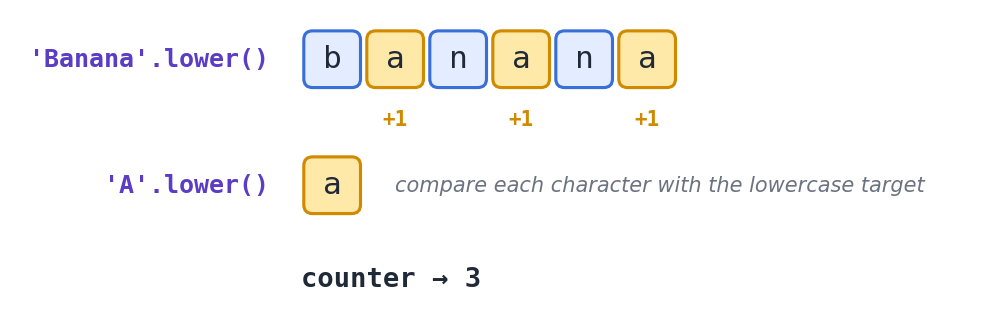

In [ ]:
counter = 0
for character in 'Banana'.lower():
    if character == 'A'.lower():
        counter = counter + 1
print(counter)

**Discuss:** How could a loop produce the same count? Why lowercase target too?

In [ ]:
def count_character(text, target):
    pass


In [ ]:
# Task 5: answer (T7.pdf, slide 22)
def count_character(text, target):
    return text.lower().count(target.lower())

Add a different input below and write down its expected result first.

## Task 6: A different palindrome rule

`is_palindrome(text)`

Check a palindrome: ignore case and whitespace, keep punctuation.

1. Ignore letter case and remove all whitespace, including tabs and line breaks.
2. Keep digits and every punctuation mark. This is not an 'ignore everything except letters' task.
3. Return True if the remaining string equals its reverse, otherwise False. Empty and whitespace-only strings return True.
4. Before coding, give an input for which removing ordinary spaces only would produce a different answer.

Input: text is an ASCII string, possibly empty. All ASCII whitespace is ignored; punctuation is kept.

Return the result; do not print inside the function.

### Examples

```python
is_palindrome('Never odd or even')
```

Returns `True`.

```python
is_palindrome('ab,ba!')
```

Returns `False`.

```python
is_palindrome('')
```

Returns `True`.


### Choose what to ignore before reversing

This task ignores whitespace and case, but keeps punctuation. Use the same cleaned string on both sides of the comparison.

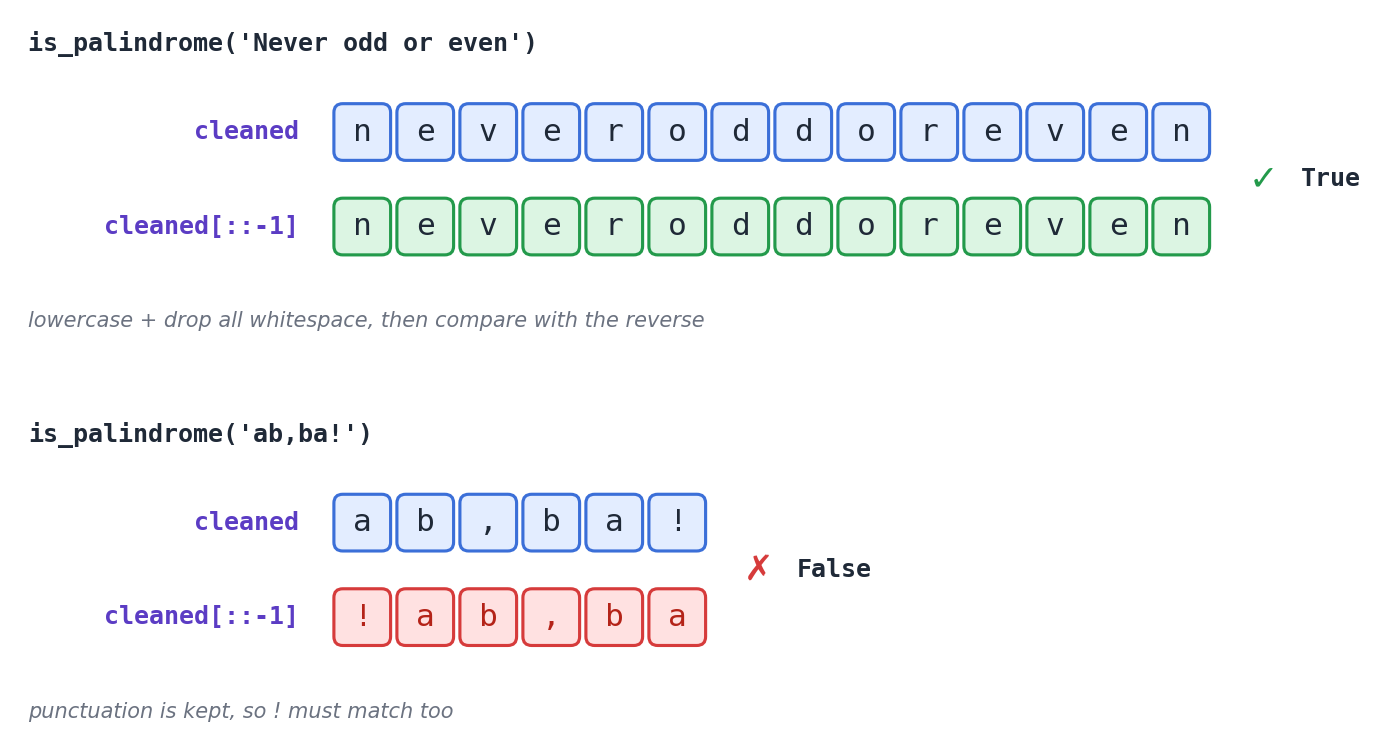

**Discuss:** Try 'a\tbba', 'ab!ba' and 'ab,ba!'. Why does replace(' ', '') miss one of these cases?

In [ ]:
def is_palindrome(text):
    pass


In [ ]:
# Task 6: answer (T7.pdf, slide 24)
def is_palindrome(text):
    compact = ''.join(text.lower().split())
    return compact == compact[::-1]

Add a different input below and write down its expected result first.

## Task 7: Mask a username

`mask_email(email)`

Hide all but the first character of an email username.

1. The input contains exactly one @, a non-empty username and a non-empty domain. It contains no whitespace. Do not validate email syntax.
2. Keep the username's first character and replace each remaining username character with one *. Keep @ and the complete domain unchanged.
3. Preserve the case of everything you keep. A one-character username stays unchanged.
4. Use the split('@') form already covered in class; the input guarantee makes a split limit unnecessary.

Input: email is an ASCII string with exactly one @, no whitespace, and non-empty parts on both sides. This is a string transformation, not an email validator.

Return the result; do not print inside the function.

### Examples

```python
mask_email('alice@example.com')
```

Returns `'a****@example.com'`.

```python
mask_email('A@HKU.HK')
```

Returns `'A@HKU.HK'`.


### Split the address into two jobs

Only the username changes. Keep its first character, repeat * for the remaining length, then put the unchanged domain back.

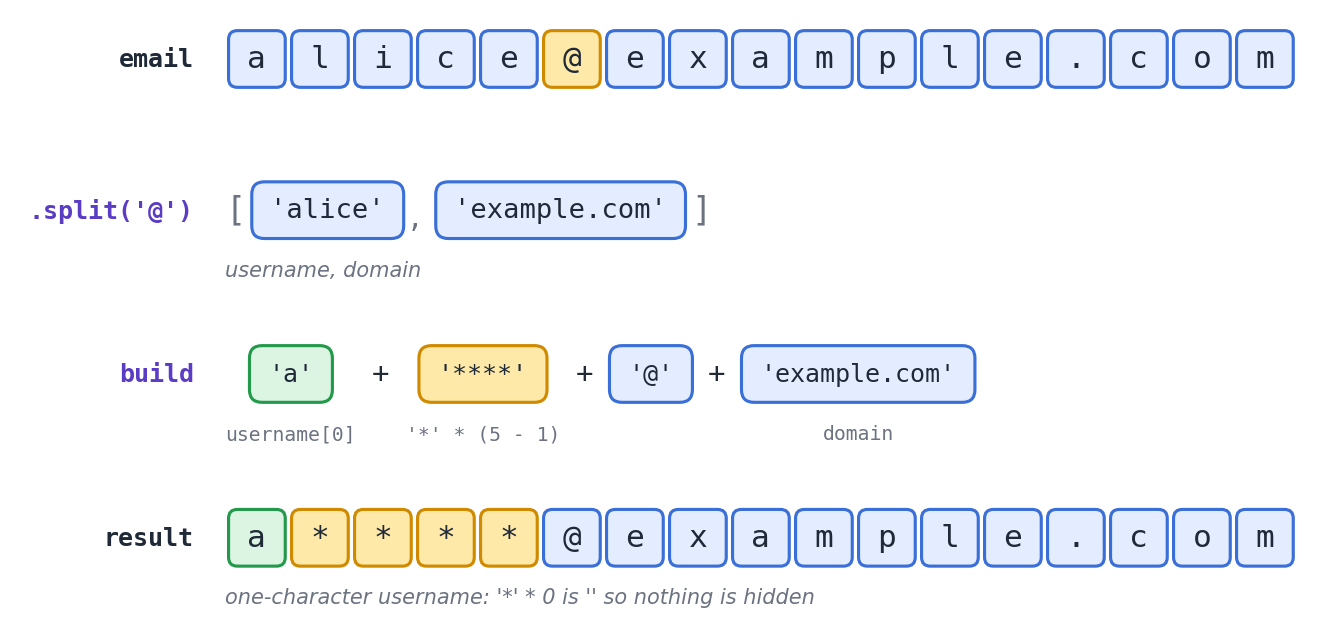

**Discuss:** For 'A@HKU.HK', how many stars are needed? Why should we not lowercase the whole address?

In [ ]:
def mask_email(email):
    pass


In [ ]:
# Task 7: answer (T7.pdf, slide 26)
def mask_email(email):
    username, domain = email.split('@')
    masked = (username[0]
              + '*' * (len(username) - 1))
    return masked + '@' + domain

Add a different input below and write down its expected result first.

## Before you finish

Try an empty input, a tie between words, and a tab instead of a space. Check that your functions return the right type and leave the original strings unchanged. Which test found a mistake in your first attempt?